# fig4 revised: consistent train features + training on train only (Recall optimization) + all-slice test evaluation

## Background

The original `fig4.ipynb` had two problems.

1. **The training image features were outdated**: in `img_path_and_clinical_info_remove_nan_img_feature_0408.csv`
   (created on 2026-04-08), the 128-dimensional features of some patients (e.g. those re-cropped manually around the centroid)
   **were extracted from old images that differ from the crops regenerated later (4/9)**.
   Because of this, some cholecystitis patients became false negatives in the all-slice evaluation.
2. **Optimizing for Accuracy tends to produce false negatives**: clinically, false negatives (missed cases) are the bigger problem, so
   the optimization metric of `tune_model` is changed from Accuracy to **Recall**.

## What this notebook does

1. `img_feature_128_train_single_test_all_slices_full_noroi_20260702_with_blood.csv`
   (train = one image per patient, **features re-extracted from the current crops**; test = all slices; including blood data) is loaded
2. PCA is fit on **all rows** of train + test (140 single-image train rows + 504 all-slice test rows), and
   the number of components needed for 90% cumulative explained variance (same criterion as cell 3 of the original fig4.ipynb) is determined automatically and applied
3. An Extra Trees model is trained on **train only** (one image per patient, 139 patients), and `tune_model` is **optimized for Recall**
4. Predicted probabilities are computed for **all test slices** (58 patients, 504 images), and scatter plots / positive fractions are visualized per patient

## Files used

- `img_feature_128_train_single_test_all_slices_full_noroi_20260702_with_blood.csv`
  must be placed in `DATA_DIR` (set in the import cell; default: the directory of this notebook).


In [ ]:
# Run once in the local environment (PyCaret 3.3 requires Python 3.9-3.11):
# pip install pycaret

In [ ]:
DATA_DIR = "."  # directory containing the input CSV files

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from pycaret.classification import *


In [ ]:
# ===== Load data =====
DATA_PATH = f"{DATA_DIR}/img_feature_128_train_single_test_all_slices_full_noroi_20260702_with_blood.csv"

#DATA_PATH = f"{DATA_DIR}/img_feature_128_train_single_test_hybrid_mask_all_slices_20260702_with_blood.csv"

df = pd.read_csv(DATA_PATH)
print("total rows:", df.shape)

# Train rows (one image per patient) have no z (NaN) and test rows (all slices) have z; use this to separate them
is_train_row = df["z"].isna()
print("train rows (one image per patient):", is_train_row.sum())
print("test rows (all slices)          :", (~is_train_row).sum())
print("train patients:", df.loc[is_train_row, "patient_id"].nunique())
print("test patients :", df.loc[~is_train_row, "patient_id"].nunique())


total rows: (644, 144)
train rows (one image per patient): 140
test rows (all slices)          : 504
train patients: 139
test patients : 58


In [ ]:
# ===== Fit PCA on all train + test rows (number of components for 80% cumulative explained variance chosen automatically) =====
img_cols = [c for c in df.columns if c.startswith("img_feat_")]
print("raw image feature dims:", len(img_cols))

# Find the number of components needed for 80% explained variance (same criterion as cell 3 of the original fig4.ipynb)
pca_full = PCA(random_state=42)
pca_full.fit(df[img_cols])
cum_var = pca_full.explained_variance_ratio_.cumsum()
n_90 = int(np.argmax(cum_var >= 0.82) + 1)
print(f"Components needed for 80% explained variance: {n_90} (actual cumulative explained variance: {cum_var[n_90-1]:.4f})")

pca = PCA(n_components=n_90, random_state=42)
img_pca = pca.fit_transform(df[img_cols])
pca_cols = [f"img_pca_{i}" for i in range(n_90)]

df_pca = pd.concat(
    [df.drop(columns=img_cols).reset_index(drop=True), pd.DataFrame(img_pca, columns=pca_cols)],
    axis=1,
)
print("df_pca shape:", df_pca.shape)


raw image feature dims: 128
Components needed for 80% explained variance: 32 (actual cumulative explained variance: 0.8243)
df_pca shape: (644, 48)


In [ ]:
# ===== Split into train (one image per patient) / test (all slices) =====
clinical_cols = ["WBC", "PLT", "CRP", "T-Bil", "AST", "ALT", "γGTP", "ALP", "Cre", "PT-INR"]

is_train_row = df_pca["z"].isna()

train_df = df_pca[is_train_row].copy()
test_df_allslices = df_pca[~is_train_row].copy()

print("train:", train_df.shape, "/", train_df["patient_id"].nunique(), "patients")
print("test (all slices):", test_df_allslices.shape, "/", test_df_allslices["patient_id"].nunique(), "patients")

feature_cols = clinical_cols + pca_cols

train_X = train_df[feature_cols + ["label"]].reset_index(drop=True)
test_X = test_df_allslices[feature_cols + ["label"]].reset_index(drop=True)

# Metadata for linking predictions back to each patient later
test_meta = test_df_allslices[["path", "z", "group", "patient_id", "local_patient_id"]].reset_index(drop=True)

train_X.head()


train: (140, 48) / 139 patients
test (all slices): (504, 48) / 58 patients


        WBC       PLT       CRP     T-Bil       AST       ALT      γGTP  \
0 -0.518660  0.808068 -0.684757 -0.657096 -0.317251 -0.319587 -0.555147   
1 -0.049564  0.841238 -0.687890 -0.358710 -0.356454 -0.331034 -0.510473   
2 -0.762637  0.122562 -0.693112 -0.458172 -0.248645 -0.273801 -0.130746   
3 -1.247841  0.244184 -0.614786 -0.756558  0.457010  1.076890 -0.510473   
4 -1.575894 -0.463435 -0.654471 -0.955482 -0.278048 -0.216568 -0.272213   

        ALP       Cre    PT-INR  ...  img_pca_23  img_pca_24  img_pca_25  \
0  0.498105 -0.521672 -0.380524  ...   -0.823913    0.685050   -0.384386   
1 -0.463694  0.216883 -0.227703  ...   -0.600530    0.265414    0.418137   
2 -0.372857  0.324964 -0.686166  ...    0.337099   -0.020282   -0.178712   
3 -0.538500 -0.413591 -0.686166  ...   -0.659175    0.069327   -0.086164   
4 -0.602620  0.180856 -0.482405  ...    0.380344   -0.137512   -0.542445   

   img_pca_26  img_pca_27  img_pca_28  img_pca_29  img_pca_30  img_pca_31  \
0   -0.633670  

## Model training (train only, Recall optimization)

The test data (all slices) is never used for training. It is not passed to `test_data` in `setup()` either, and
model selection and tuning are done only by 5-fold CV within the training data.


In [ ]:
clf = setup(
    data=train_X,
    target="label",
    fold_strategy="stratifiedkfold",
    fold=5,
    session_id=42,
    normalize=True,
)


,Description,Value
0,Session id,42
1,Target,label
2,Target type,Binary
3,Original data shape,"(140, 43)"
4,Transformed data shape,"(140, 43)"
5,Transformed train set shape,"(98, 43)"
6,Transformed test set shape,"(42, 43)"
7,Numeric features,42
8,Preprocess,True
9,Imputation type,simple


In [ ]:
# For reference: overview of which algorithms look promising (not used for the selection below, kept as a record)
compare_models()


,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC,TT (Sec)
et,Extra Trees Classifier,0.9495,0.9840,0.9200,0.9800,0.9484,0.8990,0.9018,0.1420
rf,Random Forest Classifier,0.9295,0.9708,0.9178,0.9400,0.9282,0.8588,0.8598,0.1640
nb,Naive Bayes,0.9289,0.9560,0.9200,0.9436,0.9273,0.8582,0.8660,0.0320
lightgbm,Light Gradient Boosting Machine,0.9284,0.9747,0.8978,0.9618,0.9260,0.8570,0.8634,0.1980
ada,Ada Boost Classifier,0.9279,0.9642,0.9178,0.9396,0.9260,0.8560,0.8605,0.1020
xgboost,Extreme Gradient Boosting,0.8979,0.9651,0.8578,0.9356,0.8935,0.7960,0.8012,0.0840
lr,Logistic Regression,0.8763,0.9520,0.8378,0.9236,0.8688,0.7544,0.7692,1.2440
gbc,Gradient Boosting Classifier,0.8668,0.8799,0.8578,0.8792,0.8662,0.7333,0.7372,0.1240
svm,SVM - Linear Kernel,0.8358,0.9211,0.8156,0.8740,0.8316,0.6729,0.6902,0.0480
knn,K Neighbors Classifier,0.8263,0.8860,0.6778,0.9667,0.7817,0.6562,0.6927,0.0340


Processing:   0%|          | 0/65 [00:00<?, ?it/s]

ExtraTreesClassifier(bootstrap=False, ccp_alpha=0.0, class_weight=None,
                     criterion='gini', max_depth=None, max_features='sqrt',
                     max_leaf_nodes=None, max_samples=None,
                     min_impurity_decrease=0.0, min_samples_leaf=1,
                     min_samples_split=2, min_weight_fraction_leaf=0.0,
                     monotonic_cst=None, n_estimators=100, n_jobs=-1,
                     oob_score=False, random_state=42, verbose=0,
                     warm_start=False)

In [ ]:
model = create_model('nb')


,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.9000,0.9600,0.8000,1.0000,0.8889,0.8000,0.8165
1,0.9000,0.8900,0.9000,0.9000,0.9000,0.8000,0.8000
2,0.9500,0.9800,0.9000,1.0000,0.9474,0.9000,0.9045
3,0.8947,0.9500,1.0000,0.8182,0.9000,0.7912,0.8090
4,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
Mean,0.9289,0.9560,0.9200,0.9436,0.9273,0.8582,0.8660
Std,0.0408,0.0372,0.0748,0.0737,0.0416,0.0814,0.0768


Processing:   0%|          | 0/4 [00:00<?, ?it/s]

In [ ]:
# ===== Optimize for Recall (tuning toward fewer false negatives) =====
tuned_model = tune_model(model, n_iter=15, optimize='Recall')


,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.9000,0.9600,0.8000,1.0000,0.8889,0.8000,0.8165
1,0.9000,0.8900,0.9000,0.9000,0.9000,0.8000,0.8000
2,0.9500,0.9800,0.9000,1.0000,0.9474,0.9000,0.9045
3,0.8947,0.9500,1.0000,0.8182,0.9000,0.7912,0.8090
4,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
Mean,0.9289,0.9560,0.9200,0.9436,0.9273,0.8582,0.8660
Std,0.0408,0.0372,0.0748,0.0737,0.0416,0.0814,0.0768


Processing:   0%|          | 0/7 [00:00<?, ?it/s]

Fitting 5 folds for each of 15 candidates, totalling 75 fits


Original model was better than the tuned model, hence it will be returned. NOTE: The display metrics are for the tuned model (not the original one).


In [ ]:
evaluate_model(tuned_model)


interactive(children=(ToggleButtons(description='Plot Type:', icons=('',), options=(('Pipeline Plot', 'pipelin…

## Prediction on all test slices

Predicted probabilities are computed for the 58 test patients / 504 slice images (+ blood data per patient), which were not used for training.


In [ ]:
all_slices_pred = predict_model(tuned_model, data=test_X, raw_score=True)

all_slices_pred["patient_id"] = test_meta["patient_id"].values
all_slices_pred["group"] = test_meta["group"].values
all_slices_pred["z"] = test_meta["z"].values
all_slices_pred["path"] = test_meta["path"].values
all_slices_pred.head()


,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
0,Naive Bayes,0.8790,0.9331,0.8567,0.9345,0.8939,0.7537,0.7575


        WBC       PLT       CRP     T-Bil       AST       ALT     γGTP  \
0 -0.974791  0.133618 -0.691023 -0.458172 -0.356454 -0.262354 -0.41368   
1 -0.974791  0.133618 -0.691023 -0.458172 -0.356454 -0.262354 -0.41368   
2 -0.974791  0.133618 -0.691023 -0.458172 -0.356454 -0.262354 -0.41368   
3 -0.974791  0.133618 -0.691023 -0.458172 -0.356454 -0.262354 -0.41368   
4 -0.974791  0.133618 -0.691023 -0.458172 -0.356454 -0.262354 -0.41368   

        ALP      Cre    PT-INR  ...  img_pca_30  img_pca_31  label  \
0 -0.495753 -0.05332 -0.584285  ...   -0.031796   -0.037248      0   
1 -0.495753 -0.05332 -0.584285  ...   -0.145707   -0.819183      0   
2 -0.495753 -0.05332 -0.584285  ...   -0.163985   -0.189098      0   
3 -0.495753 -0.05332 -0.584285  ...    0.147794   -0.396928      0   
4 -0.495753 -0.05332 -0.584285  ...    0.360012   -0.508868      0   

   prediction_label  prediction_score_0  prediction_score_1  patient_id  \
0                 0                 1.0                 0.0

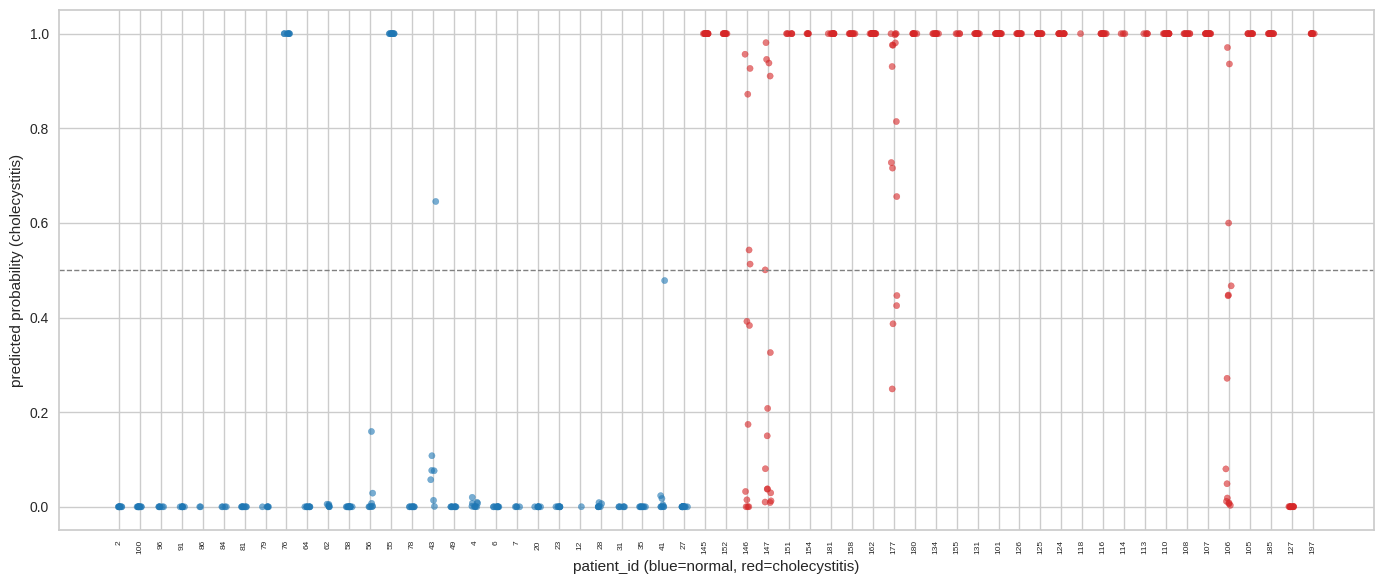

In [ ]:
# ===== Scatter plot of predicted probabilities per patient =====
fig, ax = plt.subplots(figsize=(14, 6))

patient_order = (
    all_slices_pred.groupby("patient_id")["label"].first()
    .sort_values()
    .index.tolist()
)
x_pos = {pid: i for i, pid in enumerate(patient_order)}

colors = all_slices_pred["label"].map({0: "tab:blue", 1: "tab:red"})
jitter = np.random.RandomState(0).uniform(-0.15, 0.15, size=len(all_slices_pred))
x = all_slices_pred["patient_id"].map(x_pos) + jitter

ax.scatter(x, all_slices_pred["prediction_score_1"], c=colors, alpha=0.6, s=20)
ax.axhline(0.5, linestyle="--", color="gray", linewidth=1)
ax.set_xticks(range(len(patient_order)))
ax.set_xticklabels(patient_order, rotation=90, fontsize=6)
ax.set_xlabel("patient_id (blue=normal, red=cholecystitis)")
ax.set_ylabel("predicted probability (cholecystitis)")
plt.tight_layout()
plt.savefig("all_slices_test_prob_scatter_fig4_revice_20260702.png", dpi=200, bbox_inches="tight")
plt.show()


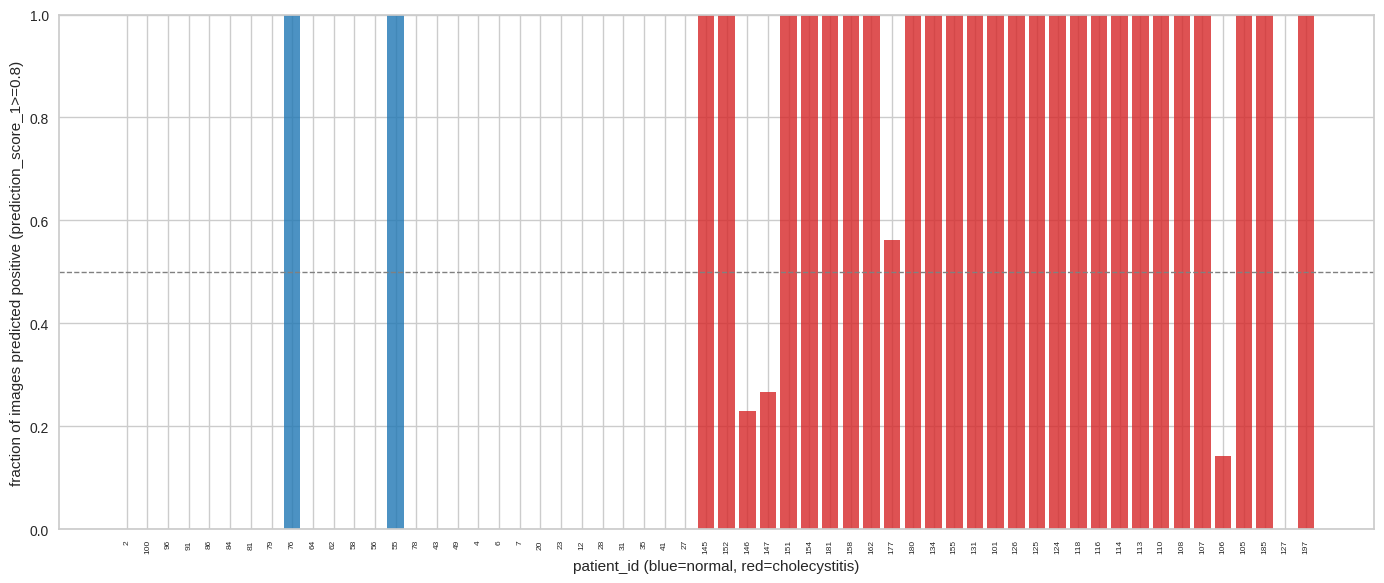

In [ ]:
#===== Fraction of positive images per patient (bar chart) =====
fig, ax = plt.subplots(figsize=(14, 6))

positive_rate = (
    all_slices_pred.assign(is_positive=(all_slices_pred["prediction_score_1"] >= 0.8))
    .groupby("patient_id")
    .agg(label=("label", "first"), positive_rate=("is_positive", "mean"), n_images=("is_positive", "count"))
    .loc[patient_order]
    .reset_index()
)

bar_colors = positive_rate["label"].map({0: "tab:blue", 1: "tab:red"})

ax.bar(range(len(patient_order)), positive_rate["positive_rate"], color=bar_colors, alpha=0.8)
ax.axhline(0.5, linestyle="--", color="gray", linewidth=1)
ax.set_xticks(range(len(patient_order)))
ax.set_xticklabels(patient_order, rotation=90, fontsize=6)
ax.set_ylim(0, 1)
ax.set_xlabel("patient_id (blue=normal, red=cholecystitis)")
ax.set_ylabel("fraction of images predicted positive (prediction_score_1>=0.8)")
plt.tight_layout()
plt.show()

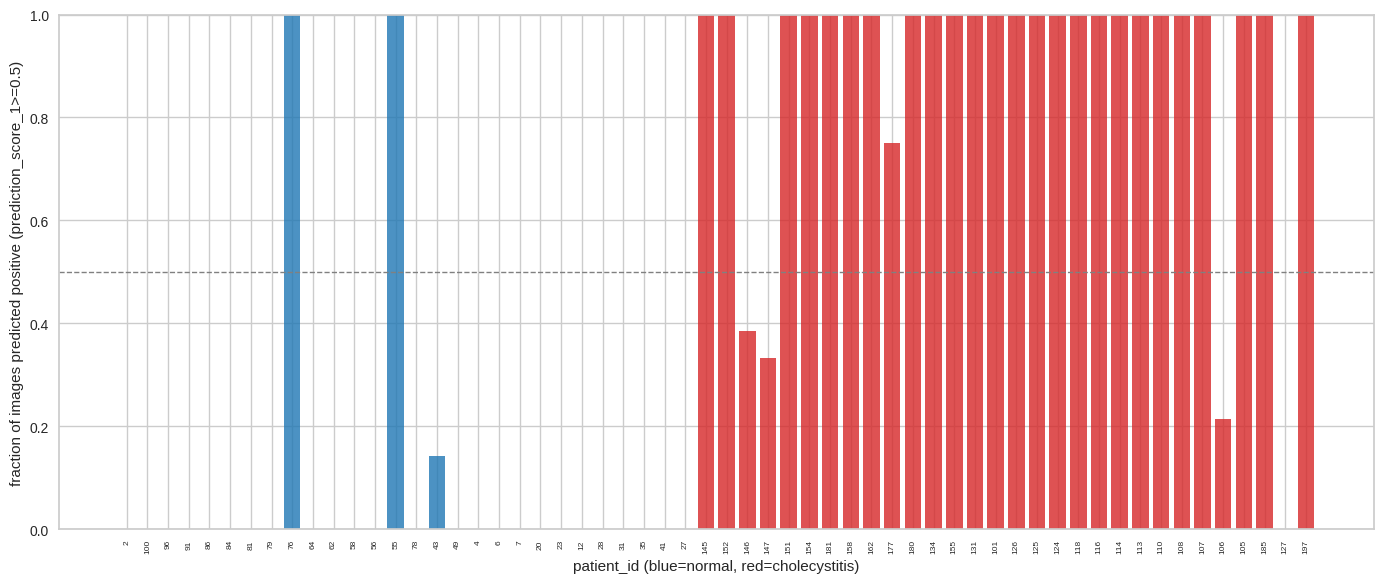

    patient_id  label  positive_rate  n_images
0            2      0       0.000000         9
1          100      0       0.000000        10
2           96      0       0.000000         6
3           91      0       0.000000         7
4           86      0       0.000000         2
5           84      0       0.000000         4
6           81      0       0.000000         8
7           79      0       0.000000         5
8           76      0       1.000000         7
9           64      0       0.000000         8
10          62      0       0.000000         6
11          58      0       0.000000        12
12          56      0       0.000000         8
13          55      0       1.000000        10
14          78      0       0.000000         8
15          43      0       0.142857         7
16          49      0       0.000000         8
17           4      0       0.000000         9
18           6      0       0.000000         9
19           7      0       0.000000         4
20          2

In [ ]:
# ===== Fraction of positive images per patient =====
fig, ax = plt.subplots(figsize=(14, 6))

positive_rate = (
    all_slices_pred.assign(is_positive=(all_slices_pred["prediction_score_1"] >= 0.5))
    .groupby("patient_id")
    .agg(label=("label", "first"), positive_rate=("is_positive", "mean"), n_images=("is_positive", "count"))
    .loc[patient_order]
    .reset_index()
)

bar_colors = positive_rate["label"].map({0: "tab:blue", 1: "tab:red"})

ax.bar(range(len(patient_order)), positive_rate["positive_rate"], color=bar_colors, alpha=0.8)
ax.axhline(0.5, linestyle="--", color="gray", linewidth=1)
ax.set_xticks(range(len(patient_order)))
ax.set_xticklabels(patient_order, rotation=90, fontsize=6)
ax.set_ylim(0, 1)
ax.set_xlabel("patient_id (blue=normal, red=cholecystitis)")
ax.set_ylabel("fraction of images predicted positive (prediction_score_1>=0.5)")
plt.tight_layout()
plt.savefig("all_slices_test_positive_rate_fig4_revice_20260702.png", dpi=200, bbox_inches="tight")
plt.show()

positive_rate


## Fit PCA on train only, then apply the same transformation to test

In [ ]:
# ===== Split into train (one image per patient) / test (all slices) (done before PCA) =====
clinical_cols = ["WBC", "PLT", "CRP", "T-Bil", "AST", "ALT", "γGTP", "ALP", "Cre", "PT-INR"]
img_cols = [c for c in df.columns if c.startswith("img_feat_")]

is_train_row = df["z"].isna()
train_raw = df[is_train_row].copy()
test_raw = df[~is_train_row].copy()

print("train:", train_raw.shape, "/", train_raw["patient_id"].nunique(), "patients")
print("test (all slices):", test_raw.shape, "/", test_raw["patient_id"].nunique(), "patients")


train: (140, 144) / 139 patients
test (all slices): (504, 144) / 58 patients


In [ ]:
# ===== Fit PCA on train only (the test set is never used, to prevent leakage) =====
# Determine the number of components for 80% cumulative explained variance from the training data only
pca_full = PCA(random_state=42)
pca_full.fit(train_raw[img_cols])
cum_var = pca_full.explained_variance_ratio_.cumsum()
n_90 = int(np.argmax(cum_var >= 0.87) + 1)
print(f"Components needed for 80% explained variance (train only): {n_90} (actual cumulative explained variance: {cum_var[n_90-1]:.4f})")

pca = PCA(n_components=n_90, random_state=42)
pca.fit(train_raw[img_cols])

pca_cols = [f"img_pca_{i}" for i in range(n_90)]

# Fit on train, transform only on test (same PCA axes)
train_pca_arr = pca.transform(train_raw[img_cols])
test_pca_arr = pca.transform(test_raw[img_cols])

train_df = pd.concat(
    [train_raw.drop(columns=img_cols).reset_index(drop=True), pd.DataFrame(train_pca_arr, columns=pca_cols)],
    axis=1,
)
test_df_allslices = pd.concat(
    [test_raw.drop(columns=img_cols).reset_index(drop=True), pd.DataFrame(test_pca_arr, columns=pca_cols)],
    axis=1,
)

print("train_df:", train_df.shape, "test_df_allslices:", test_df_allslices.shape)


Components needed for 80% explained variance (train only): 31 (actual cumulative explained variance: 0.8740)
train_df: (140, 47) test_df_allslices: (504, 47)


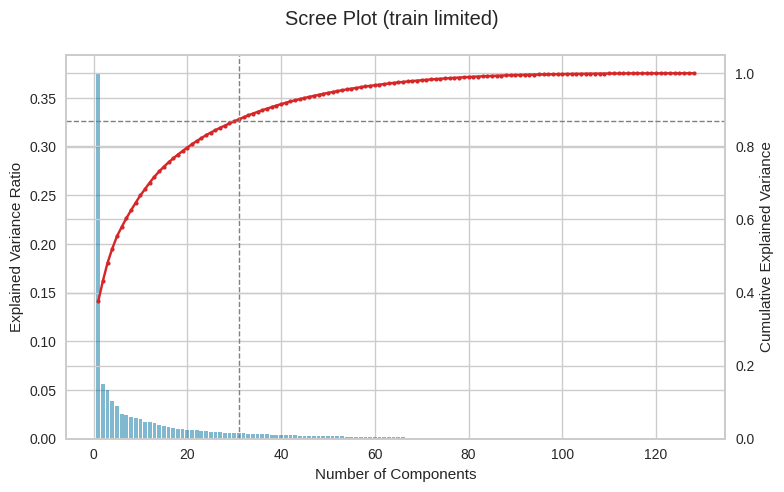

In [ ]:
# ===== Scree plot (for checking the elbow) =====
fig, ax1 = plt.subplots(figsize=(8, 5))

ax1.bar(range(1, len(pca_full.explained_variance_ratio_) + 1),
        pca_full.explained_variance_ratio_, alpha=0.5, label="explained variance (per component)")
ax1.set_xlabel("Number of Components")
ax1.set_ylabel("Explained Variance Ratio")

ax2 = ax1.twinx()
ax2.plot(range(1, len(cum_var) + 1), cum_var, color="tab:red", marker="o", markersize=3, label="cumulative")
ax2.axhline(0.87, linestyle="--", color="gray", linewidth=1)
ax2.axvline(n_90, linestyle="--", color="gray", linewidth=1)
ax2.set_ylabel("Cumulative Explained Variance")
ax2.set_ylim(0, 1.05)

fig.suptitle("Scree Plot (train limited)")
fig.tight_layout()
plt.show()

In [ ]:
# ===== Build train_X / test_X =====
feature_cols = clinical_cols + pca_cols

train_X = train_df[feature_cols + ["label"]].reset_index(drop=True)
test_X = test_df_allslices[feature_cols + ["label"]].reset_index(drop=True)

# Metadata for linking predictions back to each patient later
test_meta = test_df_allslices[["path", "z", "group", "patient_id", "local_patient_id"]].reset_index(drop=True)

train_X.head()


        WBC       PLT       CRP     T-Bil       AST       ALT      γGTP  \
0 -0.518660  0.808068 -0.684757 -0.657096 -0.317251 -0.319587 -0.555147   
1 -0.049564  0.841238 -0.687890 -0.358710 -0.356454 -0.331034 -0.510473   
2 -0.762637  0.122562 -0.693112 -0.458172 -0.248645 -0.273801 -0.130746   
3 -1.247841  0.244184 -0.614786 -0.756558  0.457010  1.076890 -0.510473   
4 -1.575894 -0.463435 -0.654471 -0.955482 -0.278048 -0.216568 -0.272213   

        ALP       Cre    PT-INR  ...  img_pca_22  img_pca_23  img_pca_24  \
0  0.498105 -0.521672 -0.380524  ...   -0.202868    1.063966    0.816795   
1 -0.463694  0.216883 -0.227703  ...   -0.292047    0.562570    0.506623   
2 -0.372857  0.324964 -0.686166  ...   -0.291384   -0.544039   -0.092181   
3 -0.538500 -0.413591 -0.686166  ...    0.056219   -0.018389    0.030990   
4 -0.602620  0.180856 -0.482405  ...   -0.180272    0.086807    0.133481   

   img_pca_25  img_pca_26  img_pca_27  img_pca_28  img_pca_29  img_pca_30  \
0   -0.138573  

## Model training (train only, Recall optimization)

The test data (all slices) is never used for training. It is not passed to `test_data` in `setup()` either, and
model selection and tuning are done only by 5-fold CV within the training data.


---



In [ ]:
from sklearn.model_selection import RepeatedStratifiedKFold
from pycaret.classification import *

rskf = RepeatedStratifiedKFold(
    n_splits=5,
    n_repeats=3,
    random_state=42
)

clf = setup(
    data=train_X,
    target="label",
    fold_strategy=rskf,
    session_id=42,
    normalize=True,
)

,Description,Value
0,Session id,42
1,Target,label
2,Target type,Binary
3,Original data shape,"(140, 42)"
4,Transformed data shape,"(140, 42)"
5,Transformed train set shape,"(98, 42)"
6,Transformed test set shape,"(42, 42)"
7,Numeric features,41
8,Preprocess,True
9,Imputation type,simple


In [ ]:
compare_models()


,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC,TT (Sec)
rf,Random Forest Classifier,0.9493,0.9825,0.9385,0.9639,0.9482,0.8984,0.9037,0.2313
et,Extra Trees Classifier,0.9493,0.9852,0.9252,0.9748,0.9471,0.8986,0.9035,0.1380
xgboost,Extreme Gradient Boosting,0.9286,0.9676,0.9052,0.9529,0.9255,0.8573,0.8624,0.0753
ada,Ada Boost Classifier,0.8914,0.9649,0.8904,0.8991,0.8914,0.7826,0.7892,0.0960
nb,Naive Bayes,0.8911,0.9583,0.8704,0.9143,0.8878,0.7824,0.7889,0.0320
lightgbm,Light Gradient Boosting Machine,0.8744,0.9650,0.8644,0.8947,0.8736,0.7485,0.7586,0.1427
lr,Logistic Regression,0.8737,0.9505,0.8422,0.9044,0.8673,0.7470,0.7557,0.0353
knn,K Neighbors Classifier,0.8535,0.9293,0.7741,0.9211,0.8361,0.7063,0.7207,0.0307
svm,SVM - Linear Kernel,0.8533,0.9184,0.8563,0.8545,0.8516,0.7064,0.7134,0.0293
dt,Decision Tree Classifier,0.8500,0.8496,0.8504,0.8678,0.8521,0.6993,0.7109,0.0320


Processing:   0%|          | 0/65 [00:00<?, ?it/s]

RandomForestClassifier(bootstrap=True, ccp_alpha=0.0, class_weight=None,
                       criterion='gini', max_depth=None, max_features='sqrt',
                       max_leaf_nodes=None, max_samples=None,
                       min_impurity_decrease=0.0, min_samples_leaf=1,
                       min_samples_split=2, min_weight_fraction_leaf=0.0,
                       monotonic_cst=None, n_estimators=100, n_jobs=-1,
                       oob_score=False, random_state=42, verbose=0,
                       warm_start=False)

In [ ]:
model = create_model('et')


,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.9000,0.9800,0.9000,0.9000,0.9000,0.8000,0.8000
1,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
2,0.9500,0.9850,0.9000,1.0000,0.9474,0.9000,0.9045
3,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
4,0.8947,0.9333,0.8000,1.0000,0.8889,0.7912,0.8090
5,0.8500,0.9200,0.8000,0.8889,0.8421,0.7000,0.7035
6,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
7,0.9500,1.0000,0.9000,1.0000,0.9474,0.9000,0.9045
8,0.9474,1.0000,0.8889,1.0000,0.9412,0.8939,0.8989


Processing:   0%|          | 0/4 [00:00<?, ?it/s]

In [ ]:
# ===== Optimize for Recall (tuning toward fewer false negatives) =====
tuned_model = tune_model(model, n_iter=15, optimize='Accuracy')


,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.9000,0.9800,0.9000,0.9000,0.9000,0.8000,0.8000
1,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
2,0.9500,1.0000,0.9000,1.0000,0.9474,0.9000,0.9045
3,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
4,0.8947,0.9667,0.8000,1.0000,0.8889,0.7912,0.8090
5,0.9000,0.9200,0.9000,0.9000,0.9000,0.8000,0.8000
6,0.9500,1.0000,0.9000,1.0000,0.9474,0.9000,0.9045
7,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
8,0.9474,1.0000,0.8889,1.0000,0.9412,0.8939,0.8989


Processing:   0%|          | 0/7 [00:00<?, ?it/s]

Fitting 15 folds for each of 15 candidates, totalling 225 fits


In [ ]:
evaluate_model(tuned_model)


interactive(children=(ToggleButtons(description='Plot Type:', icons=('',), options=(('Pipeline Plot', 'pipelin…

## Prediction on all test slices

Predicted probabilities are computed for the 58 test patients / 504 slice images (+ blood data per patient), which were not used for training.


In [ ]:
all_slices_pred = predict_model(tuned_model, data=test_X, raw_score=True)

all_slices_pred["patient_id"] = test_meta["patient_id"].values
all_slices_pred["group"] = test_meta["group"].values
all_slices_pred["z"] = test_meta["z"].values
all_slices_pred["path"] = test_meta["path"].values

all_slices_pred.head()


,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
0,Extra Trees Classifier,0.8929,0.9776,0.8533,0.9624,0.9046,0.7834,0.7908


        WBC       PLT       CRP     T-Bil       AST       ALT     γGTP  \
0 -0.974791  0.133618 -0.691023 -0.458172 -0.356454 -0.262354 -0.41368   
1 -0.974791  0.133618 -0.691023 -0.458172 -0.356454 -0.262354 -0.41368   
2 -0.974791  0.133618 -0.691023 -0.458172 -0.356454 -0.262354 -0.41368   
3 -0.974791  0.133618 -0.691023 -0.458172 -0.356454 -0.262354 -0.41368   
4 -0.974791  0.133618 -0.691023 -0.458172 -0.356454 -0.262354 -0.41368   

        ALP      Cre    PT-INR  ...  img_pca_29  img_pca_30  label  \
0 -0.495753 -0.05332 -0.584285  ...   -0.144803    0.359226      0   
1 -0.495753 -0.05332 -0.584285  ...   -0.247447    0.079563      0   
2 -0.495753 -0.05332 -0.584285  ...    0.586335   -0.017032      0   
3 -0.495753 -0.05332 -0.584285  ...    1.021724    0.079103      0   
4 -0.495753 -0.05332 -0.584285  ...    0.355184    0.222838      0   

   prediction_label  prediction_score_0  prediction_score_1  patient_id  \
0                 0              0.7050              0.2950

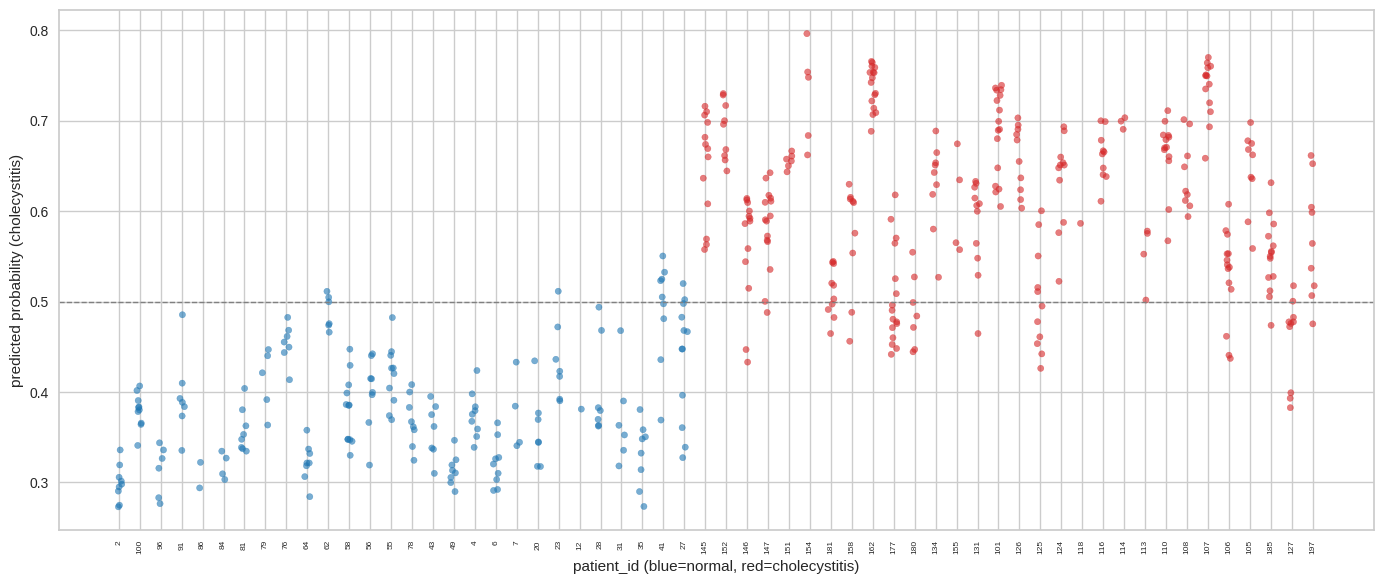

In [ ]:
# ===== Scatter plot of predicted probabilities per patient =====
fig, ax = plt.subplots(figsize=(14, 6))

patient_order = (
    all_slices_pred.groupby("patient_id")["label"].first()
    .sort_values()
    .index.tolist()
)
x_pos = {pid: i for i, pid in enumerate(patient_order)}

colors = all_slices_pred["label"].map({0: "tab:blue", 1: "tab:red"})
jitter = np.random.RandomState(0).uniform(-0.15, 0.15, size=len(all_slices_pred))
x = all_slices_pred["patient_id"].map(x_pos) + jitter

ax.scatter(x, all_slices_pred["prediction_score_1"], c=colors, alpha=0.6, s=20)
ax.axhline(0.5, linestyle="--", color="gray", linewidth=1)
ax.set_xticks(range(len(patient_order)))
ax.set_xticklabels(patient_order, rotation=90, fontsize=6)
ax.set_xlabel("patient_id (blue=normal, red=cholecystitis)")
ax.set_ylabel("predicted probability (cholecystitis)")
plt.tight_layout()
#plt.savefig("all_slices_test_prob_scatter_fig4_revice_20260702.png", dpi=200, bbox_inches="tight")
plt.show()


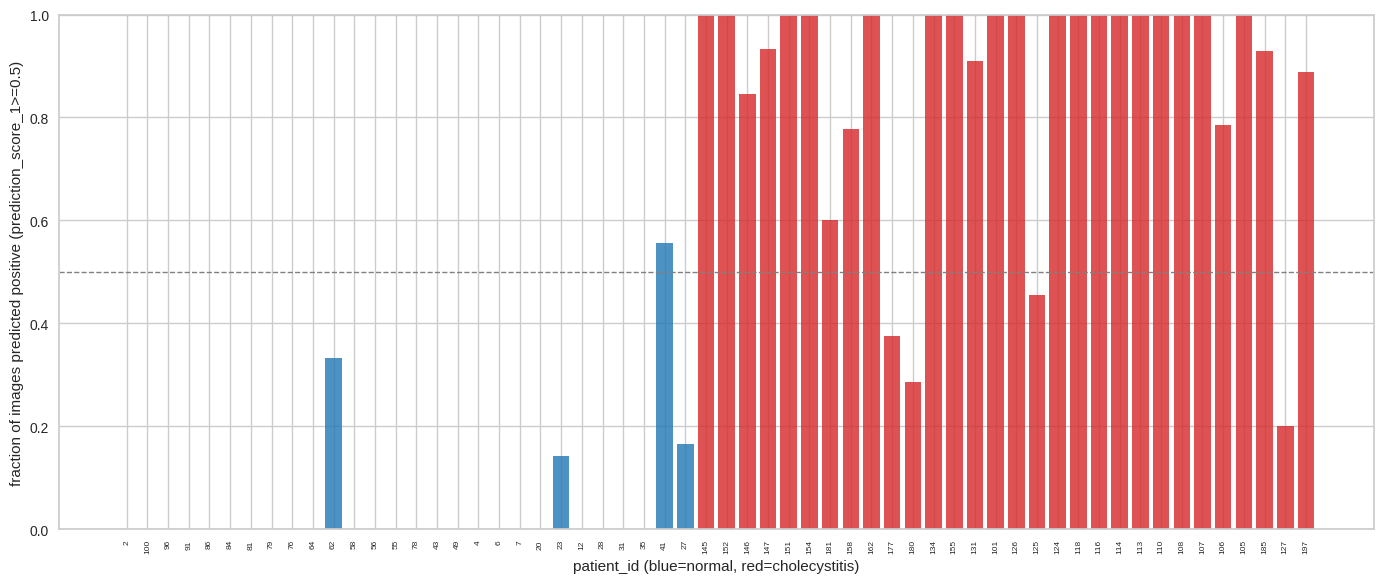

In [ ]:
# ===== Fraction of positive images per patient =====
fig, ax = plt.subplots(figsize=(14, 6))

positive_rate = (
    all_slices_pred.assign(is_positive=(all_slices_pred["prediction_score_1"] >= 0.5))
    .groupby("patient_id")
    .agg(label=("label", "first"), positive_rate=("is_positive", "mean"), n_images=("is_positive", "count"))
    .loc[patient_order]
    .reset_index()
)

bar_colors = positive_rate["label"].map({0: "tab:blue", 1: "tab:red"})

ax.bar(range(len(patient_order)), positive_rate["positive_rate"], color=bar_colors, alpha=0.8)
ax.axhline(0.5, linestyle="--", color="gray", linewidth=1)
ax.set_xticks(range(len(patient_order)))
ax.set_xticklabels(patient_order, rotation=90, fontsize=6)
ax.set_ylim(0, 1)
ax.set_xlabel("patient_id (blue=normal, red=cholecystitis)")
ax.set_ylabel("fraction of images predicted positive (prediction_score_1>=0.5)")
plt.tight_layout()
#plt.savefig("all_slices_test_positive_rate_fig4_revice_20260702.png", dpi=200, bbox_inches="tight")
plt.show()


In [ ]:
# 1) Finalize the model by retraining it on the full dataset
model_final = finalize_model(tuned_model)

# 2) Access the underlying Random Forest classifier from the pipeline
rf = model_final.named_steps["actual_estimator"]

# 3) Obtain the feature names used during model training
feature_names = get_config("X_train").columns

# 4) feature importance
fi = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf.feature_importances_
}).sort_values("Importance", ascending=False)

display(fi.head(10))

       Feature  Importance
10   img_pca_0    0.228563
2          CRP    0.154994
0          WBC    0.099515
7          ALP    0.062933
3        T-Bil    0.051061
9       PT-INR    0.034362
6         γGTP    0.022316
40  img_pca_30    0.021474
4          AST    0.019080
5          ALT    0.019050

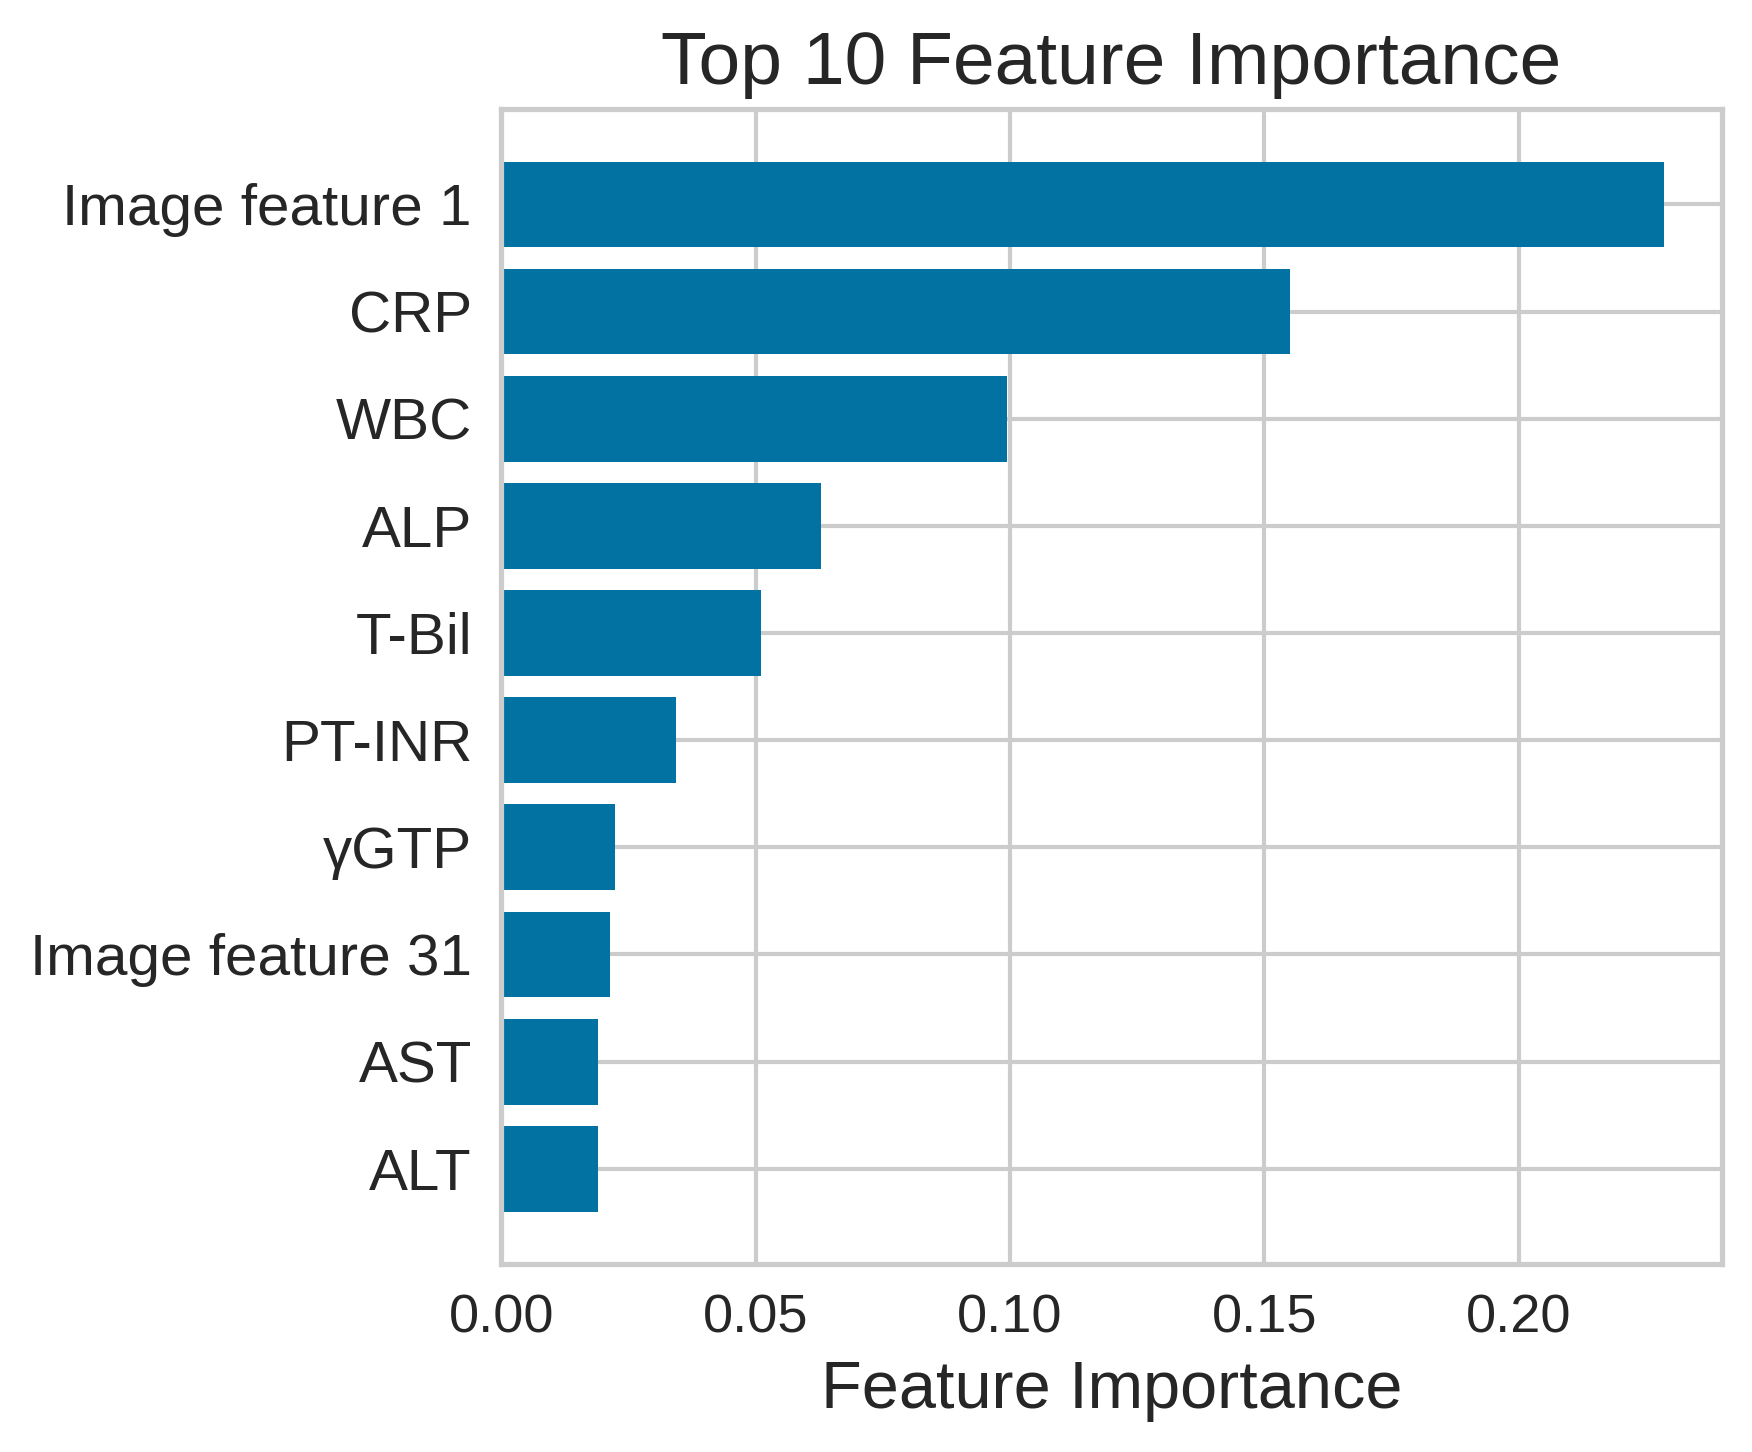

In [ ]:
fi_top = fi.head(10).iloc[::-1].copy()

def rename_feature(x):
    if str(x).startswith("img_pca_"):
        num = int(x.split("_")[-1]) + 1
        return f"Image feature {num}"
    else:
        return x

fi_top["Feature"] = fi_top["Feature"].apply(rename_feature)

import matplotlib.pyplot as plt

plt.figure(figsize=(6, 5), dpi=300)

plt.barh(fi_top["Feature"], fi_top["Importance"])

plt.xlabel("Feature Importance", fontsize=16)
plt.title("Top 10 Feature Importance", fontsize=18)

plt.xticks(fontsize=13)
plt.yticks(fontsize=14)

plt.tight_layout()
plt.show()

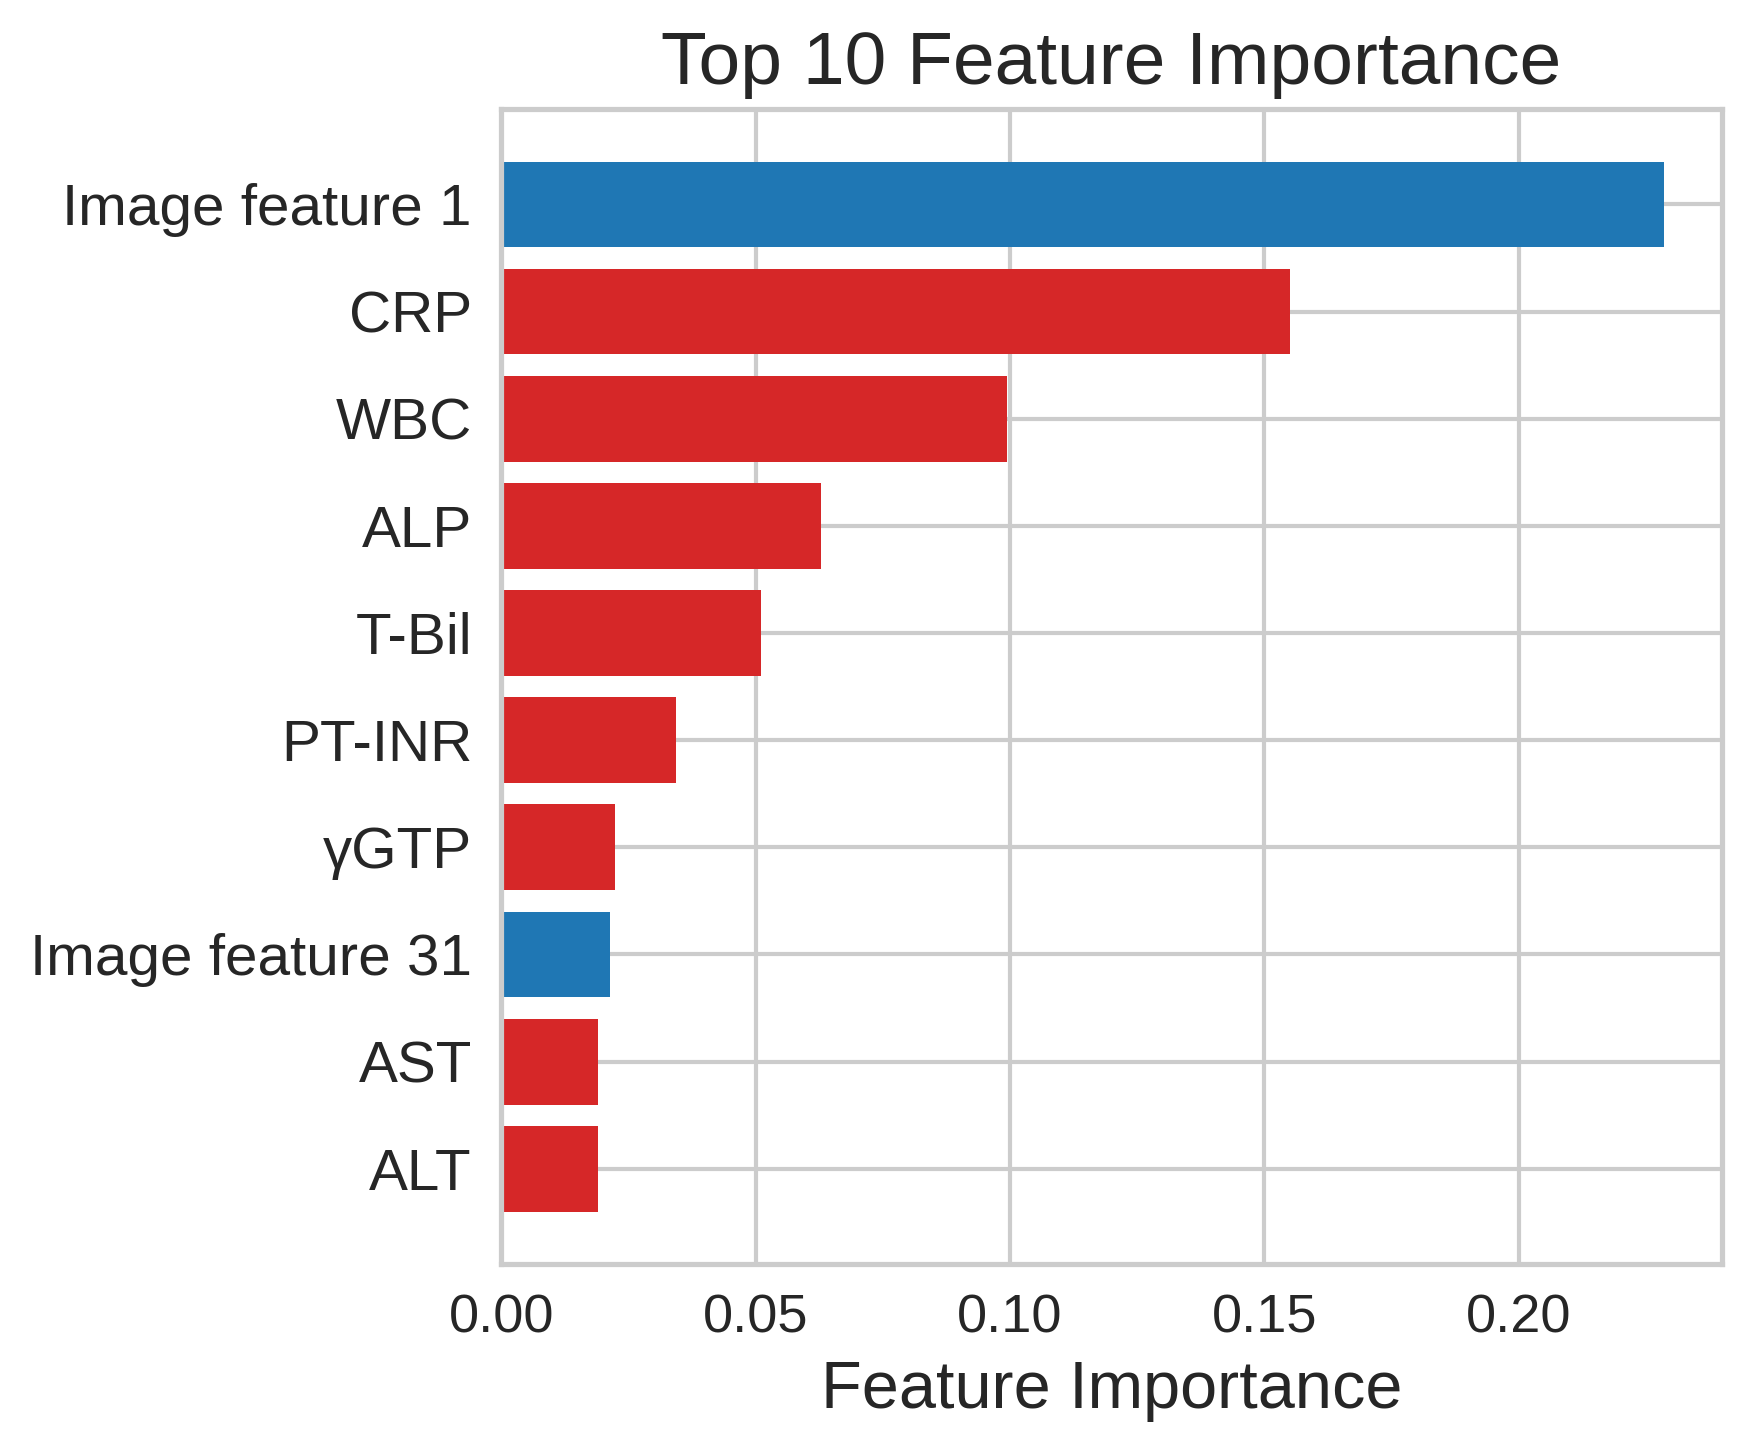

In [ ]:
colors = [
    "tab:blue" if "Image feature" in f else "tab:red"
    for f in fi_top["Feature"]
]

plt.figure(figsize=(6, 5), dpi=300)
plt.barh(fi_top["Feature"], fi_top["Importance"], color=colors)

plt.xlabel("Feature Importance", fontsize=16)
plt.title("Top 10 Feature Importance", fontsize=18)

plt.xticks(fontsize=13)
plt.yticks(fontsize=14)

plt.tight_layout()
plt.show()

    n_components  cv_recall  cv_recall_sd  cv_accuracy  cv_accuracy_sd
0             10   0.934286      0.062007     0.959286        0.035000
1             11   0.937143      0.064902     0.958571        0.036673
2             12   0.930000      0.061429     0.955714        0.033166
3             13   0.924286      0.067627     0.954286        0.039149
4             14   0.924286      0.061296     0.953571        0.034442
5             15   0.938571      0.062286     0.957143        0.035714
6             16   0.938571      0.060626     0.958571        0.035254
7             17   0.934286      0.058624     0.957857        0.033266
8             18   0.930000      0.063068     0.955714        0.035399
9             19   0.931429      0.063824     0.955714        0.035399
10            20   0.940000      0.062857     0.961429        0.035600
11            21   0.938571      0.053471     0.960714        0.031339
12            22   0.921429      0.073193     0.951429        0.039615
13    

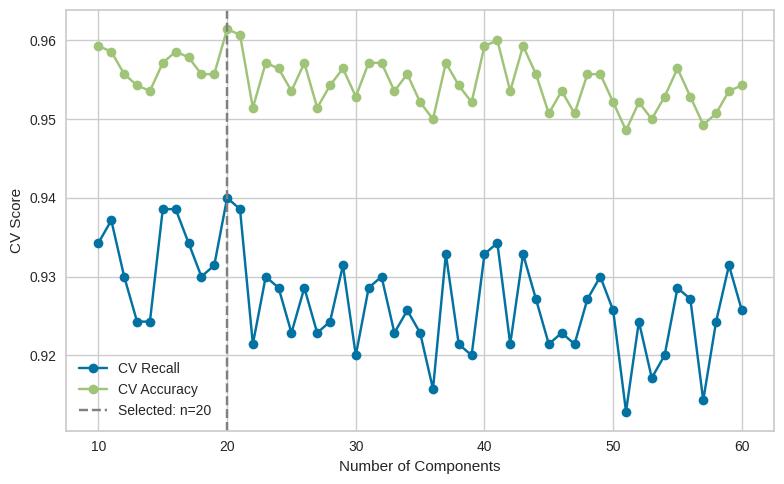

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.model_selection import (
    StratifiedKFold,
    cross_validate
)
from sklearn.pipeline import Pipeline

X_train_for_cv = train_raw[clinical_cols + img_cols].copy()
y_train_for_cv = train_raw["label"].values

candidates = list(range(10, 61))

from sklearn.model_selection import RepeatedStratifiedKFold

cv = RepeatedStratifiedKFold(
    n_splits=5,
    n_repeats=10,
    random_state=42
)

cv_results = []

for n in candidates:

    preprocess = ColumnTransformer(
        transformers=[
            # Apply PCA to the image features only
            ("image_pca", PCA(n_components=n), img_cols),

            # Use the blood data as is
            ("clinical", "passthrough", clinical_cols)
        ],
        remainder="drop"
    )

    pipeline = Pipeline(
        steps=[
            ("preprocess", preprocess),
            (
                "classifier",
                ExtraTreesClassifier(
                    n_estimators=100,
                    random_state=42,
                    n_jobs=-1
                )
            )
        ]
    )

    scores = cross_validate(
        pipeline,
        X_train_for_cv,
        y_train_for_cv,
        cv=cv,
        scoring={
            "recall": "recall",
            "accuracy": "accuracy"
        },
        n_jobs=-1,
        return_train_score=False
    )

    cv_results.append(
        {
            "n_components": n,
            "cv_recall": scores["test_recall"].mean(),
            "cv_recall_sd": scores["test_recall"].std(),
            "cv_accuracy": scores["test_accuracy"].mean(),
            "cv_accuracy_sd": scores["test_accuracy"].std()
        }
    )

df_cv_results = pd.DataFrame(cv_results)

best_row = (
    df_cv_results
    .sort_values(
        ["cv_recall", "cv_accuracy", "n_components"],
        ascending=[False, False, True]
    )
    .iloc[0]
)

best_n_by_recall = int(best_row["n_components"])

print(df_cv_results)
print("Selected number of components:", best_n_by_recall)
print("CV Recall:", best_row["cv_recall"])
print("CV Accuracy:", best_row["cv_accuracy"])

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    df_cv_results["n_components"],
    df_cv_results["cv_recall"],
    marker="o",
    label="CV Recall"
)

ax.plot(
    df_cv_results["n_components"],
    df_cv_results["cv_accuracy"],
    marker="o",
    label="CV Accuracy"
)

ax.axvline(
    best_n_by_recall,
    linestyle="--",
    color="gray",
    label=f"Selected: n={best_n_by_recall}"
)

ax.set_xlabel("Number of Components")
ax.set_ylabel("CV Score")
ax.legend()

plt.tight_layout()
plt.show()

## Evaluation with confidence intervals

Add 95% confidence intervals to the results of the 58 test patients (patient level).

- accuracy / sensitivity / specificity / PPV / NPV: Wilson score interval (confidence interval for a proportion)
- AUC / F1: stratified bootstrap (patients resampled with replacement within positives and negatives separately, 2000 resamples, percentile method)
- The threshold is fixed at 0.5 (positive if the maximum predicted probability within the patient is >= 0.5, i.e. positive if any slice is positive)

In [ ]:
# ===== Functions for metrics and 95% confidence intervals =====
# Proportion metrics use the Wilson score interval; AUC and F1 use a stratified bootstrap (percentile method).
from sklearn.metrics import roc_auc_score, confusion_matrix, f1_score

THRESHOLD = 0.5
N_BOOT = 2000
SEED = 42

def wilson_ci(k, n, z=1.96):
    if n == 0:
        return np.nan, np.nan
    p = k / n
    denom = 1 + z**2 / n
    center = (p + z**2 / (2 * n)) / denom
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denom
    return center - half, center + half

def bootstrap_ci(y_true, y_prob, stat_fn, n_boot=N_BOOT, seed=SEED):
    # Resample within each class so that every bootstrap sample contains both positives and negatives
    rng = np.random.default_rng(seed)
    pos = np.where(y_true == 1)[0]
    neg = np.where(y_true == 0)[0]
    vals = []
    for _ in range(n_boot):
        idx = np.concatenate([rng.choice(pos, len(pos), replace=True), rng.choice(neg, len(neg), replace=True)])
        vals.append(stat_fn(y_true[idx], y_prob[idx]))
    return np.percentile(vals, 2.5), np.percentile(vals, 97.5)

def compute_metrics(y_true, y_prob, threshold=THRESHOLD):
    y_true = np.asarray(y_true).astype(int)
    y_prob = np.asarray(y_prob, dtype=float)
    y_pred = (y_prob >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()

    f1_fn = lambda yt, yp: f1_score(yt, (yp >= threshold).astype(int), zero_division=0)
    rows = [
        ("AUC", roc_auc_score(y_true, y_prob), *bootstrap_ci(y_true, y_prob, roc_auc_score)),
        ("accuracy", (tp + tn) / len(y_true), *wilson_ci(tp + tn, len(y_true))),
        ("sensitivity", tp / (tp + fn), *wilson_ci(tp, tp + fn)),
        ("specificity", tn / (tn + fp), *wilson_ci(tn, tn + fp)),
        ("PPV", tp / (tp + fp) if tp + fp > 0 else np.nan, *wilson_ci(tp, tp + fp)),
        ("NPV", tn / (tn + fn) if tn + fn > 0 else np.nan, *wilson_ci(tn, tn + fn)),
        ("F1", f1_fn(y_true, y_prob), *bootstrap_ci(y_true, y_prob, f1_fn)),
    ]
    df = pd.DataFrame(rows, columns=["metric", "value", "ci_low", "ci_high"])
    df["value_95ci"] = df.apply(lambda r: f"{r['value']:.3f} ({r['ci_low']:.3f}-{r['ci_high']:.3f})", axis=1)
    counts = {"n": len(y_true), "TN": tn, "FP": fp, "FN": fn, "TP": tp}
    return df, counts

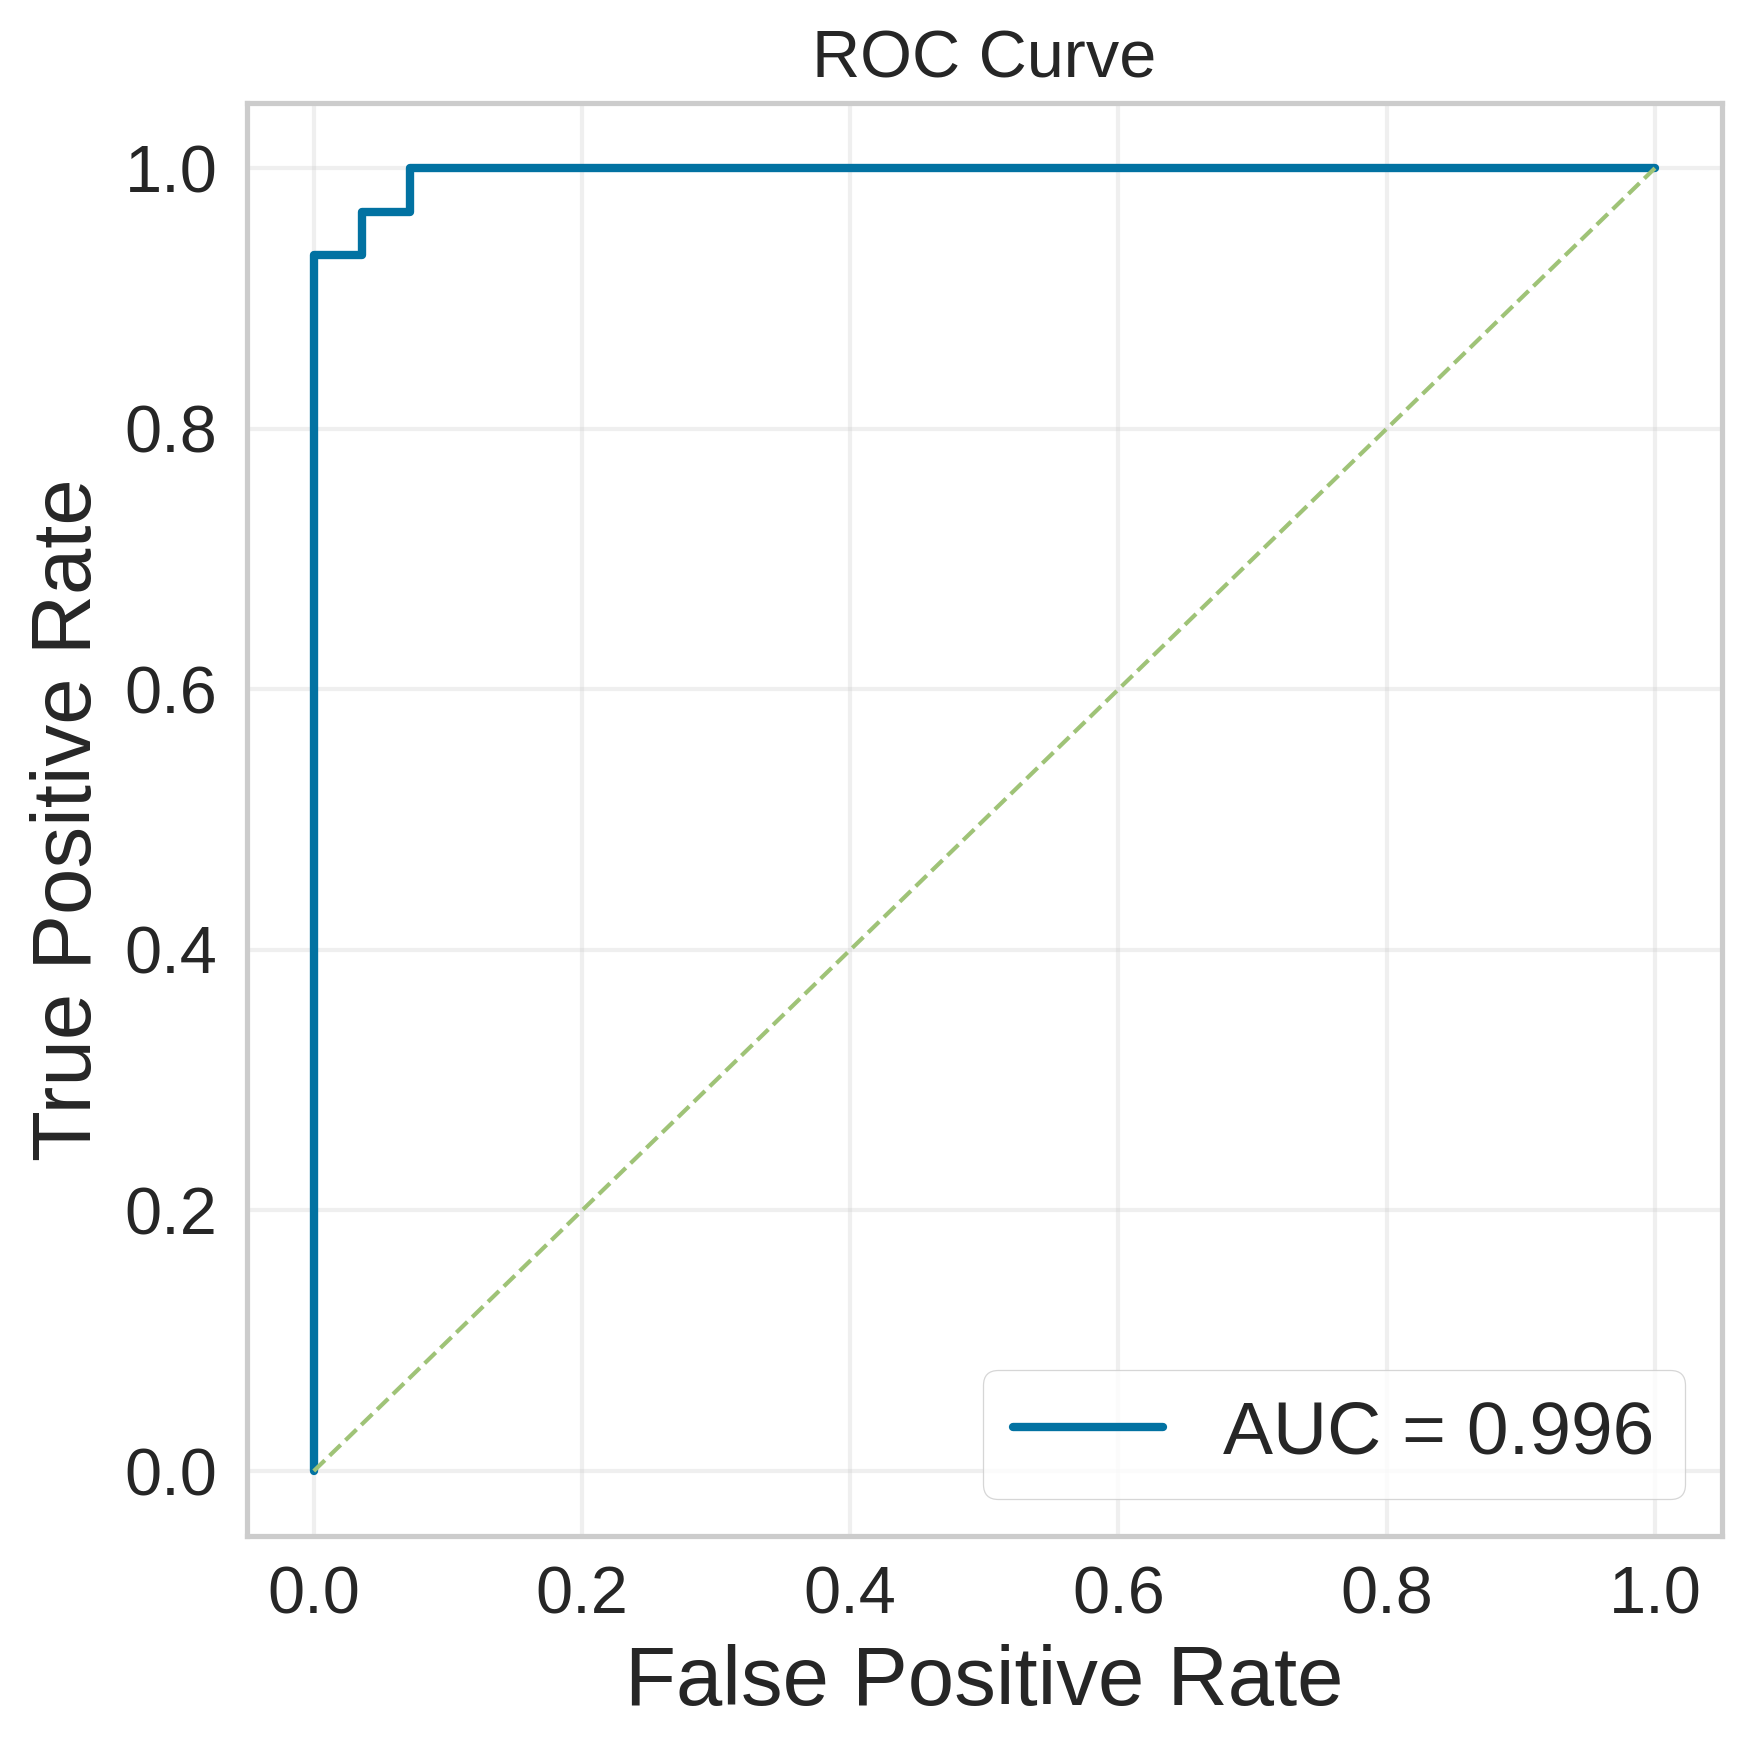

In [ ]:
# ===== Patient-level evaluation: a patient is positive if any slice is positive (>= 0.5) =====
from sklearn.metrics import roc_curve, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay, classification_report

# Maximum predicted probability per patient (if any slice is high, it represents the whole patient)
patient_level = (
    all_slices_pred.groupby("patient_id")
    .agg(label=("label", "first"), max_prob=("prediction_score_1", "max"))
    .reset_index()
)

y_true_patient = patient_level["label"].values
y_score_patient = patient_level["max_prob"].values
y_pred_patient = (y_score_patient >= 0.5).astype(int)  # positive if any slice is >= 0.5

# ===== ROC curve =====
fpr, tpr, _ = roc_curve(y_true_patient, y_score_patient)
auc = roc_auc_score(y_true_patient, y_score_patient)
auc_lo, auc_hi = bootstrap_ci(y_true_patient, y_score_patient, roc_auc_score)

fig, ax = plt.subplots(figsize=(6, 6), dpi=300)
ax.plot(fpr, tpr, linewidth=2, label=f"AUC = {auc:.3f}\n(95% CI {auc_lo:.3f}-{auc_hi:.3f})")
ax.plot([0, 1], [0, 1], linestyle="--", linewidth=1)
ax.set_xlabel("False Positive Rate", fontsize=20)
ax.set_ylabel("True Positive Rate", fontsize=20)
ax.set_title("ROC Curve", fontsize=16)
ax.tick_params(axis='both', labelsize=16)
ax.legend(fontsize=18, loc="lower right", frameon=True)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


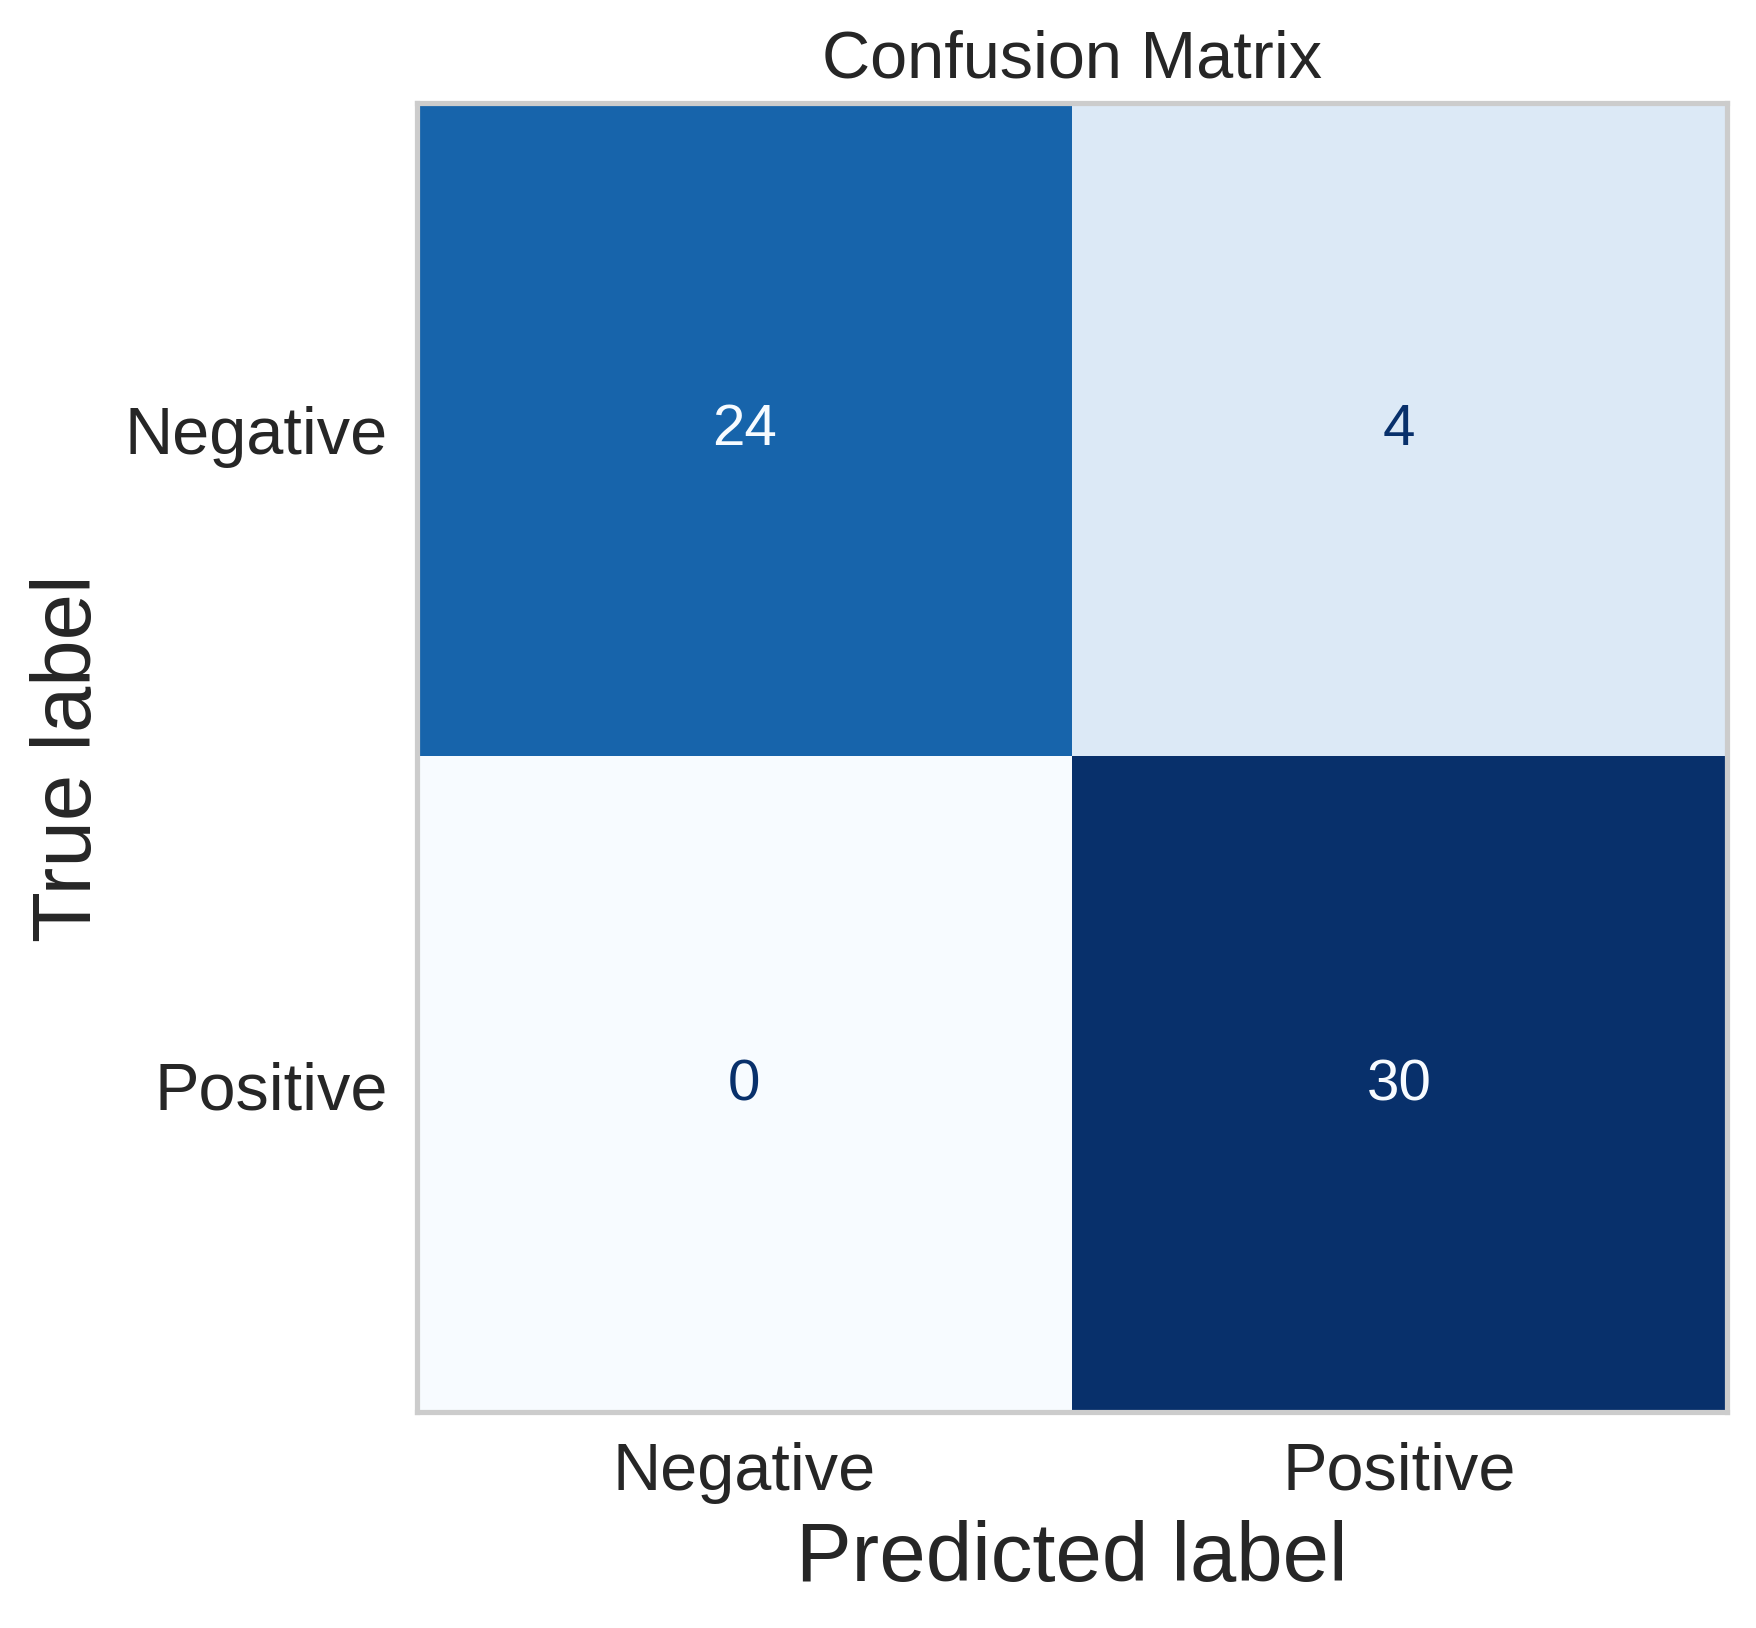

              precision    recall  f1-score   support

    Negative      1.000     0.857     0.923        28
    Positive      0.882     1.000     0.938        30

    accuracy                          0.931        58
   macro avg      0.941     0.929     0.930        58
weighted avg      0.939     0.931     0.931        58



In [ ]:
# ===== Confusion matrix =====
cm = confusion_matrix(y_true_patient, y_pred_patient)
fig, ax = plt.subplots(figsize=(6, 6), dpi=300)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Negative", "Positive"])
disp.plot(cmap=plt.cm.Blues, ax=ax, colorbar=False)
ax.grid(False)
ax.set_title("Confusion Matrix", fontsize=16)
ax.set_xlabel("Predicted label", fontsize=20)
ax.set_ylabel("True label", fontsize=20)
ax.tick_params(axis="both", labelsize=16)
for text in disp.text_.ravel():
    text.set_fontsize(14)
plt.tight_layout()
plt.show()

print(classification_report(y_true_patient, y_pred_patient, target_names=["Negative", "Positive"], digits=3))

In [ ]:
# ===== Metrics with 95% confidence intervals (patient level, positive if any slice is positive) =====
df_metrics, counts = compute_metrics(y_true_patient, y_score_patient)
print(counts)
display(df_metrics[["metric", "value_95ci", "value", "ci_low", "ci_high"]].round(3))

df_metrics.assign(**counts).to_csv(
    f"{DATA_DIR}/fig4_revice_all_slices_any_positive_metrics_95ci.csv",
    index=False,
)

In [ ]:
# ===== Load data =====
BACKGROUND_PATH = f"{DATA_DIR}/非胆嚢炎背景.tsv"

back_df = pd.read_csv(BACKGROUND_PATH, sep='\t')
esophageal_ids = back_df[back_df["疾患区分"] == "食道癌"]["No."].astype(str).to_list()

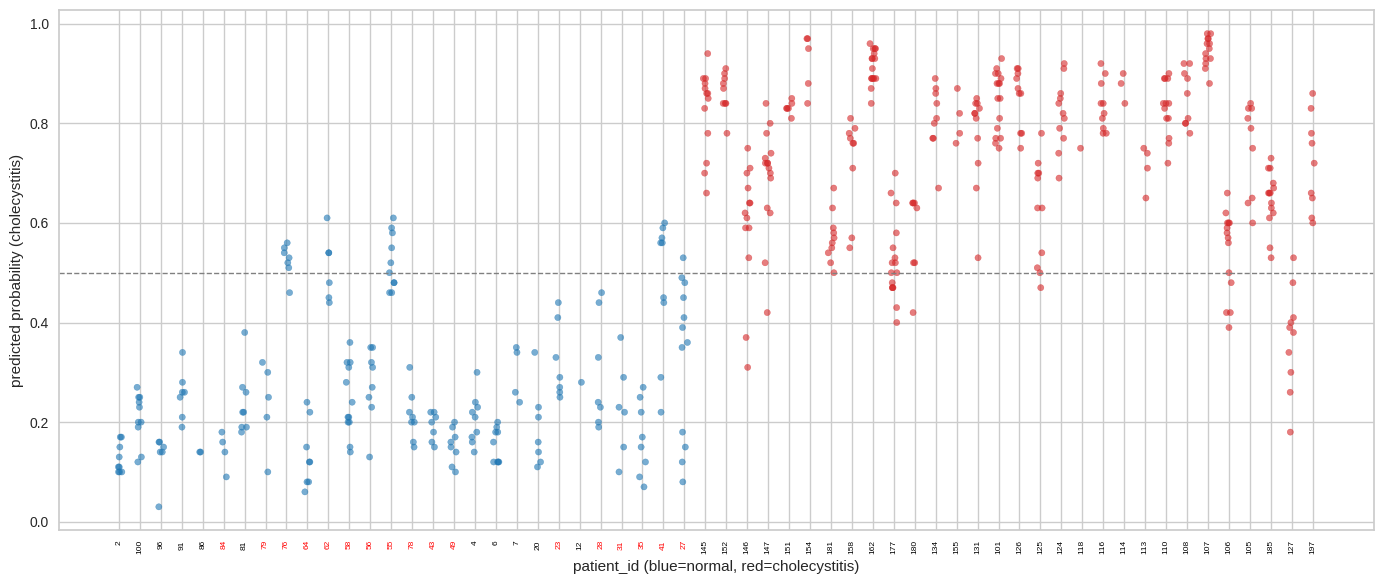

In [ ]:
esophageal_ids = (
    back_df.loc[back_df["疾患区分"] == "食道癌", "No."]
    .astype(str)
    .to_list()
)

esophageal_ids_set = set(esophageal_ids)

fig, ax = plt.subplots(figsize=(14, 6))

patient_order = (
    all_slices_pred.groupby("patient_id")["label"].first()
    .sort_values()
    .index.tolist()
)

x_pos = {pid: i for i, pid in enumerate(patient_order)}

colors = all_slices_pred["label"].map({0: "tab:blue", 1: "tab:red"})

jitter = np.random.RandomState(0).uniform(-0.15, 0.15, size=len(all_slices_pred))
x = all_slices_pred["patient_id"].map(x_pos) + jitter

ax.scatter(
    x,
    all_slices_pred["prediction_score_1"],
    c=colors,
    alpha=0.6,
    s=20
)

ax.axhline(0.5, linestyle="--", color="gray", linewidth=1)

ax.set_xticks(range(len(patient_order)))
ax.set_xticklabels(patient_order, rotation=90, fontsize=6)

for tick_label in ax.get_xticklabels():
    if str(tick_label.get_text()) in esophageal_ids_set:
        tick_label.set_color("red")
    else:
        tick_label.set_color("black")

ax.set_xlabel("patient_id (blue=normal, red=cholecystitis)")
ax.set_ylabel("predicted probability (cholecystitis)")

plt.tight_layout()
plt.show()

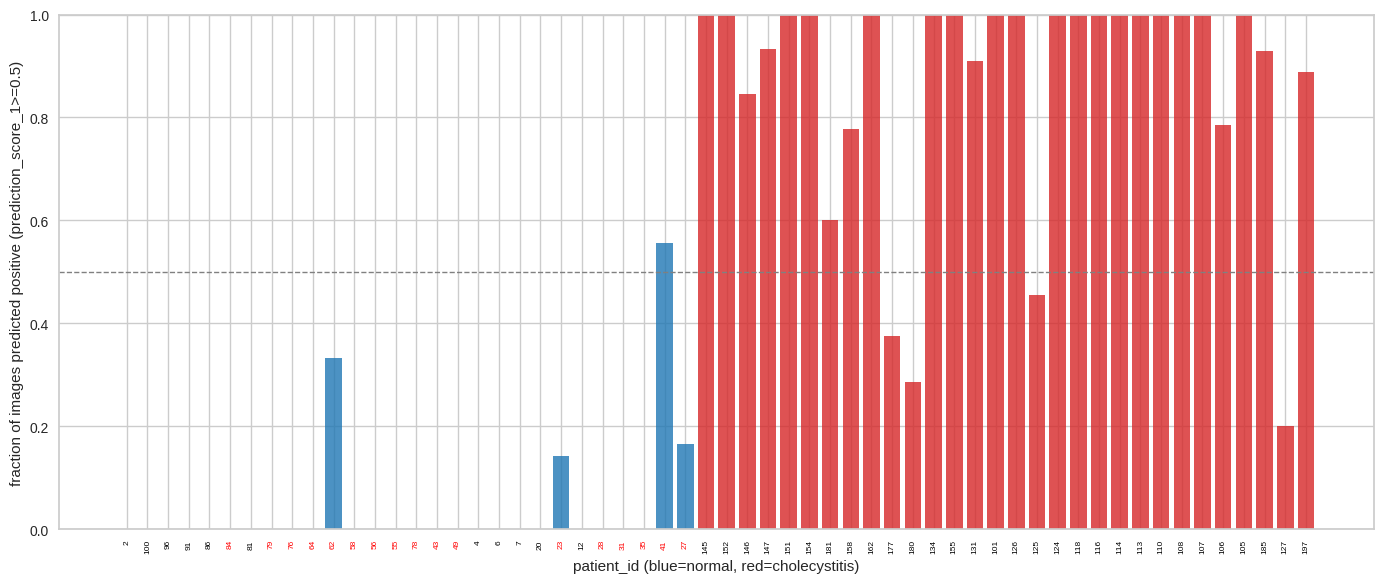

In [ ]:
esophageal_ids = (
    back_df.loc[back_df["疾患区分"] == "食道癌", "No."]
    .astype(str)
    .to_list()
)

esophageal_ids_set = set(esophageal_ids)

fig, ax = plt.subplots(figsize=(14, 6))

positive_rate = (
    all_slices_pred.assign(is_positive=(all_slices_pred["prediction_score_1"] >= 0.5))
    .groupby("patient_id")
    .agg(
        label=("label", "first"),
        positive_rate=("is_positive", "mean"),
        n_images=("is_positive", "count")
    )
    .loc[patient_order]
    .reset_index()
)

bar_colors = positive_rate["label"].map({0: "tab:blue", 1: "tab:red"})

ax.bar(
    range(len(patient_order)),
    positive_rate["positive_rate"],
    color=bar_colors,
    alpha=0.8
)

ax.axhline(0.5, linestyle="--", color="gray", linewidth=1)

ax.set_xticks(range(len(patient_order)))
ax.set_xticklabels(patient_order, rotation=90, fontsize=6)

for tick_label in ax.get_xticklabels():
    if str(tick_label.get_text()) in esophageal_ids_set:
        tick_label.set_color("red")
    else:
        tick_label.set_color("black")

ax.set_ylim(0, 1)
ax.set_xlabel("patient_id (blue=normal, red=cholecystitis)")
ax.set_ylabel("fraction of images predicted positive (prediction_score_1>=0.5)")

plt.tight_layout()
plt.show()